# Kennzahlen aus CVAT-annotierten Bildern

Dieses Notebook berechnet Kennzahlen aus den CVAT-Masken:
- Pixelanteile pro Klasse
- Klassen-Entropie (Szenen-Komplexitaet)
- Instanzzaehlung mit Connected Components (CC)
- Alternative Instanzzaehlung mit Watershed
- Alternative Instanzzaehlung mit Distanz-Peaks

Am Ende gibt es eine kompakte Vergleichstabelle der Instanzmethoden.


## Imports und Pfade
Wir lesen die CVAT-Labelmap (RGB -> Klassenname) und nutzen zusaetzlich `labels.py`, um `trainId`/`id` pro Klasse zu kennen. Die Pfade zeigen auf `05_evaluation/CVATAnnotations` (oder `05_evaluation/CVAT Annotations`, je nach Ordnername).


In [69]:
from pathlib import Path
import sys
import math

import numpy as np
import pandas as pd
from PIL import Image
import cv2
import matplotlib.pyplot as plt

# Repo-Root finden: vom aktuellen cwd nach oben, suche nach Ordnernamen mit/ohne Leerzeichen
CWD = Path.cwd().resolve()
CANDIDATE_NAMES = [
    ("05_evaluation", "CVATAnnotations"),
    ("05_evaluation", "CVAT Annotations"),
]
REPO_ROOT = None
ANNOTATION_DIR = None
for cand in [CWD, *CWD.parents]:
    for p1, p2 in CANDIDATE_NAMES:
        candidate_dir = cand / p1 / p2
        if candidate_dir.exists():
            REPO_ROOT = cand
            ANNOTATION_DIR = candidate_dir
            break
    if REPO_ROOT is not None:
        break

if REPO_ROOT is None or ANNOTATION_DIR is None:
    raise AssertionError(
        f"Kann Repo-Root nicht finden. Bitte Notebook im Repo oder Unterordner starten. CWD={CWD}"
    )

LABELMAP_PATH = ANNOTATION_DIR / "labelmap.txt"

assert ANNOTATION_DIR.exists(), f"Ordner fehlt: {ANNOTATION_DIR}"
assert LABELMAP_PATH.exists(), f"labelmap.txt fehlt: {LABELMAP_PATH}"

# labels.py fuer trainId/id Mapping laden
if str(REPO_ROOT) not in sys.path:
    sys.path.append(str(REPO_ROOT))
try:
    from labels import name2label
except ImportError as exc:
    raise ImportError("labels.py konnte nicht geladen werden. Bitte Notebook aus dem Repo-Root starten.") from exc


## Einstellungen
Hier kann ich steuern, welche Ausgaben/Plots erscheinen und welche Parameter die Instanzmethoden nutzen.


In [70]:
# Ausgabe-Schalter
SHOW_LABELMAP = True
SHOW_SUMMARY_TABLES = True
SHOW_BASIC_PLOTS = True
SHOW_PER_IMAGE_PLOTS = True
SHOW_STACKED_INSTANCES = True
SHOW_WS_PLOTS = True
SHOW_FINAL_SUMMARY = True
SHOW_FINAL_VISUALS = True
SHOW_FINAL_ALL_CLASSES = True
SHOW_PER_IMAGE_METHODS = True
PER_IMAGE_MAX = None  # z.B. 5, um nur die ersten N Bilder zu plotten

# Klassen-Filter fuer Entropie
IGNORE_TRAIN_IDS = {255, -1}
IGNORE_NAMES = {"background"}

# Klassen, die fuer WS/Peaks gezaehlt werden; None = alle Klassen
INSTANCE_CLASSES = None

# Watershed-Parameter
WS_DIST_REL = 0.20
WS_MIN_AREA = 6
WS_ERODE_ITERS = 1
WS_USE_PEAKS = True
WS_PEAK_EPS = 1e-6
WS_SEED_OPEN_KERNEL = 1  # 1 = kein Open; 3/5 macht Seeds kleiner

# Peak-Detection-Parameter
PEAK_DIST_REL = 0.20
PEAK_MIN_DISTANCE = 6
PEAK_ERODE_ITERS = 1

# Finale Visualisierung
FINAL_TOP_CLASSES = None  # z.B. 10, um nur die Top-K Klassen zu zeigen


## Labelmap einlesen
Wir lesen `labelmap.txt` (RGB-Farbe -> Klassenname) und ergaenzen `trainId`/`id` aus `labels.py`.


In [71]:
def load_labelmap(labelmap_path: Path):
    classes = []
    color_to_class = {}

    for line in labelmap_path.read_text(encoding="utf-8").splitlines():
        line = line.strip()
        if not line or line.startswith("#"):
            continue
        try:
            name, rest = line.split(":", 1)
            color_str = rest.split(":", 1)[0]
        except ValueError:
            continue

        rgb = tuple(int(c) for c in color_str.split(","))
        train_id = name2label[name].trainId if name in name2label else None
        rec = {
            "class_id": len(classes),
            "name": name,
            "color": rgb,
            "trainId": train_id,
            "id": name2label[name].id if name in name2label else None,
        }
        classes.append(rec)
        color_to_class[rgb] = rec

    return classes, color_to_class

classes, color_to_class = load_labelmap(LABELMAP_PATH)
class_names = [c["name"] for c in classes]

if SHOW_LABELMAP:
    display(pd.DataFrame(classes)[["class_id", "name", "color", "trainId", "id"]])


,class_id,name,color,trainId,id
0,0,background,"(0, 0, 0)",NaN,NaN
1,1,bicycle,"(119, 11, 32)",17.0,33.0
2,2,building,"(70, 70, 70)",3.0,11.0
3,3,bus,"(0, 60, 100)",14.0,28.0
4,4,car,"(0, 0, 142)",12.0,26.0
5,5,guard rail,"(180, 165, 180)",4.0,14.0
6,6,motorcycle,"(0, 0, 230)",16.0,32.0
7,7,parking,"(250, 170, 160)",255.0,9.0
8,8,person,"(220, 20, 60)",10.0,24.0
9,9,pole,"(153, 153, 153)",5.0,17.0


## Grundlegende Kennzahlen (Pixel, Entropie, CC)
Pixelanteile und Entropie werden direkt aus den Masken berechnet. Instanzen basieren auf Connected Components (CC).


In [72]:
def compute_metrics(
    mask_path: Path,
    classes,
    color_to_class,
    ignore_train_ids=None,
    ignore_names=None,
):
    if ignore_train_ids is None:
        ignore_train_ids = set()
    if ignore_names is None:
        ignore_names = set()

    mask = np.array(Image.open(mask_path))
    if mask.ndim != 3 or mask.shape[2] != 3:
        raise ValueError(f"Maske {mask_path} hat unerwartete Form: {mask.shape}")

    h, w, _ = mask.shape
    total_pixels = h * w
    name_to_rec = {c["name"]: c for c in classes}

    # Pixel pro Klasse (RGB -> Name)
    class_counts = {c["name"]: 0 for c in classes}
    flat = mask.reshape(-1, 3)
    colors, counts = np.unique(flat, axis=0, return_counts=True)
    for color, count in zip(colors, counts):
        rec = color_to_class.get(tuple(color.tolist()))
        if rec is None:
            continue
        class_counts[rec["name"]] += int(count)

    # Instanzanzahl pro Klasse via Connected Components
    class_instances = {c["name"]: 0 for c in classes}
    for rec in classes:
        color = np.array(rec["color"], dtype=np.uint8)
        binary = np.all(mask == color, axis=2).astype(np.uint8)
        num_components, _ = cv2.connectedComponents(binary)
        class_instances[rec["name"]] = max(num_components - 1, 0)

    # Pixelanteile
    class_shares = {
        name: (count / total_pixels if total_pixels else 0.0)
        for name, count in class_counts.items()
    }

    def is_ignored(name: str) -> bool:
        rec = name_to_rec[name]
        return (rec["trainId"] in ignore_train_ids) or (name in ignore_names)

    # Entropie nur ueber gueltige Klassen
    valid_pixel_sum = sum(count for name, count in class_counts.items() if not is_ignored(name))
    entropy = 0.0
    if valid_pixel_sum > 0:
        for name, count in class_counts.items():
            if is_ignored(name) or count == 0:
                continue
            p = count / valid_pixel_sum
            entropy -= p * math.log(p)

    present_classes = [name for name, count in class_counts.items() if count > 0 and not is_ignored(name)]

    return {
        "image": mask_path.name,
        "width": w,
        "height": h,
        "total_pixels": total_pixels,
        "class_counts": class_counts,
        "class_shares": class_shares,
        "instance_counts": class_instances,
        "entropy": entropy,
        "num_present_classes": len(present_classes),
        "present_classes": present_classes,
    }


## Auswertung ueber alle CVAT-Masken
Hier wird alles berechnet und in DataFrames abgelegt.


In [73]:
png_files = sorted(ANNOTATION_DIR.glob("*.png"))
assert png_files, "Keine *.png Masken im Ordner gefunden."

rows = [
    compute_metrics(
        png,
        classes,
        color_to_class,
        ignore_train_ids=IGNORE_TRAIN_IDS,
        ignore_names=IGNORE_NAMES,
    )
    for png in png_files
]

summary_df = pd.DataFrame({
    "image": [r["image"] for r in rows],
    "height": [r["height"] for r in rows],
    "width": [r["width"] for r in rows],
    "entropy": [r["entropy"] for r in rows],
    "num_present_classes": [r["num_present_classes"] for r in rows],
    "present_classes": [", ".join(r["present_classes"]) for r in rows],
}).set_index("image")

counts_df = pd.DataFrame([r["class_counts"] for r in rows], index=[r["image"] for r in rows]).fillna(0).astype(int)
shares_df = pd.DataFrame([r["class_shares"] for r in rows], index=[r["image"] for r in rows]).fillna(0.0)
instances_df = pd.DataFrame([r["instance_counts"] for r in rows], index=[r["image"] for r in rows]).fillna(0).astype(int)

mean_shares = shares_df.mean().sort_values(ascending=False)
class_summary_df = pd.DataFrame({
    "mean_share": mean_shares,
    "total_pixels": counts_df.sum().reindex(mean_shares.index).fillna(0).astype(int),
    "total_instances_cc": instances_df.sum().reindex(mean_shares.index).fillna(0).astype(int),
})

# Einheitliche Farbpalette pro Klasse
classes_for_plots = mean_shares.index.tolist()
cmap = plt.get_cmap("tab20")
palette = {cls: cmap(i % cmap.N) for i, cls in enumerate(classes_for_plots)}

if SHOW_SUMMARY_TABLES:
    display(summary_df)
    display(class_summary_df)


,height,width,entropy,num_present_classes,present_classes
image,,,,,
bild1.png,1536,2048,1.241006,14,"bicycle, building, bus, car, motorcycle, perso..."
bild2.png,1382,2047,1.249154,12,"bicycle, building, bus, car, person, pole, rid..."
bild3.png,1536,2048,1.501315,12,"bicycle, building, car, person, pole, rider, r..."


,mean_share,total_pixels,total_instances_cc
sky,0.409967,3730533,27
road,0.213259,1971131,57
building,0.212780,1892836,63
sidewalk,0.056073,514774,41
vegetation,0.040003,377516,28
car,0.033030,308226,18
background,0.014896,140088,134
traffic sign,0.006487,60447,44
pole,0.006008,55115,90
traffic light,0.002579,23741,55


## Visualisierung (Basis)
Basisplots fuer Pixelanteile und CC-Instanzen. Schalter in den Einstellungen steuern die Ausgabe.


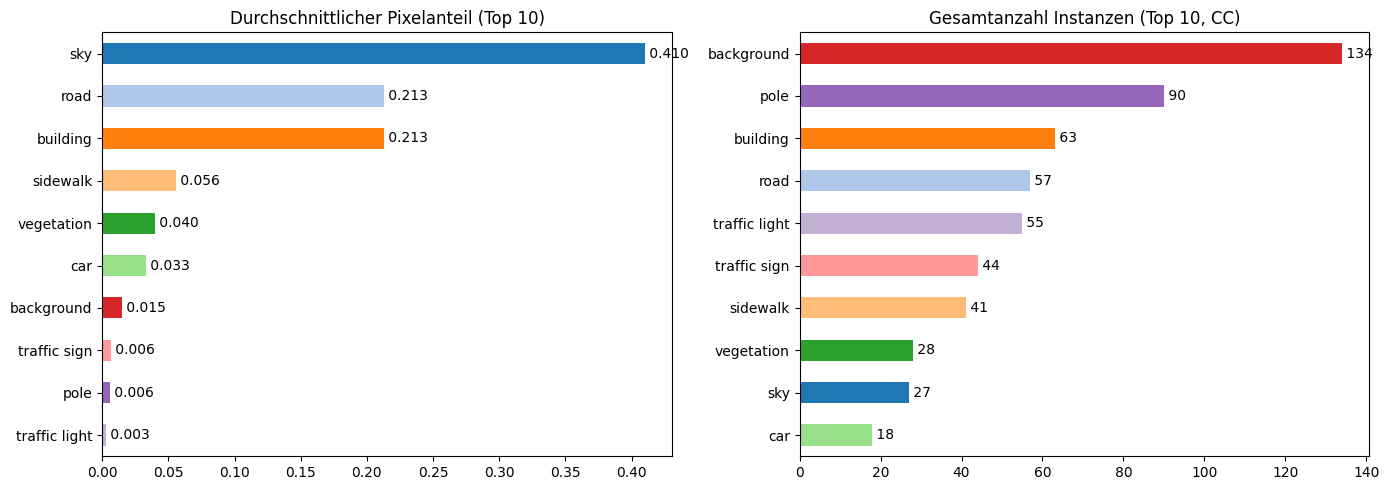

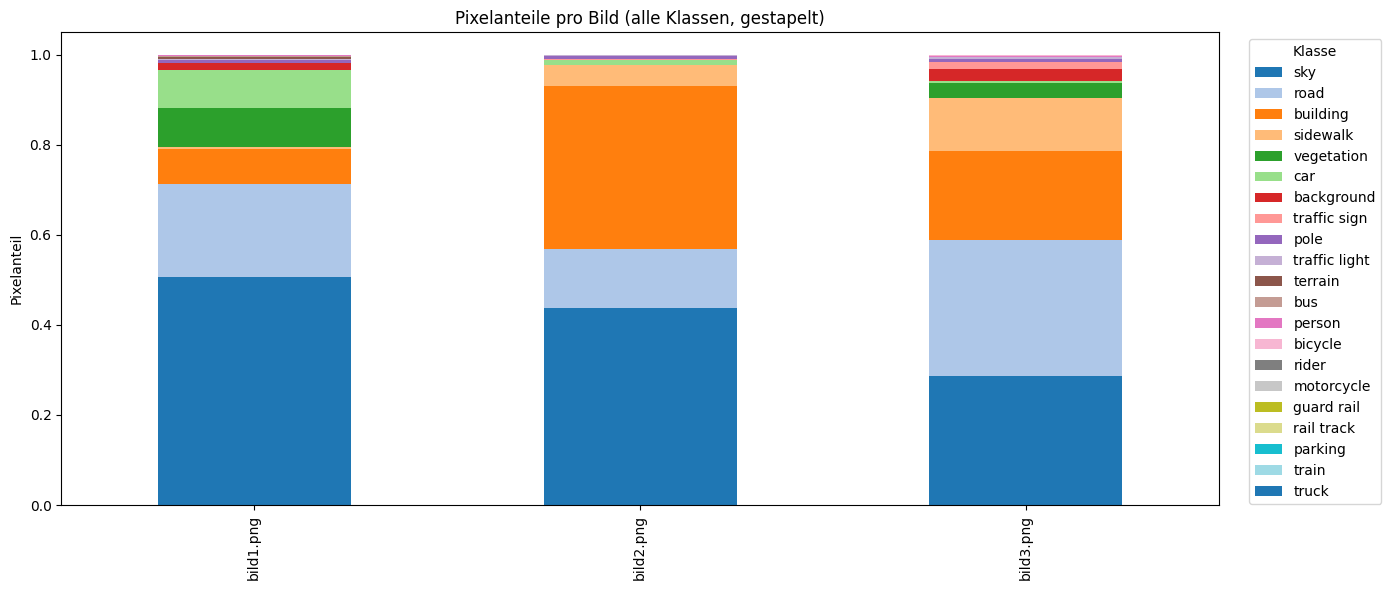

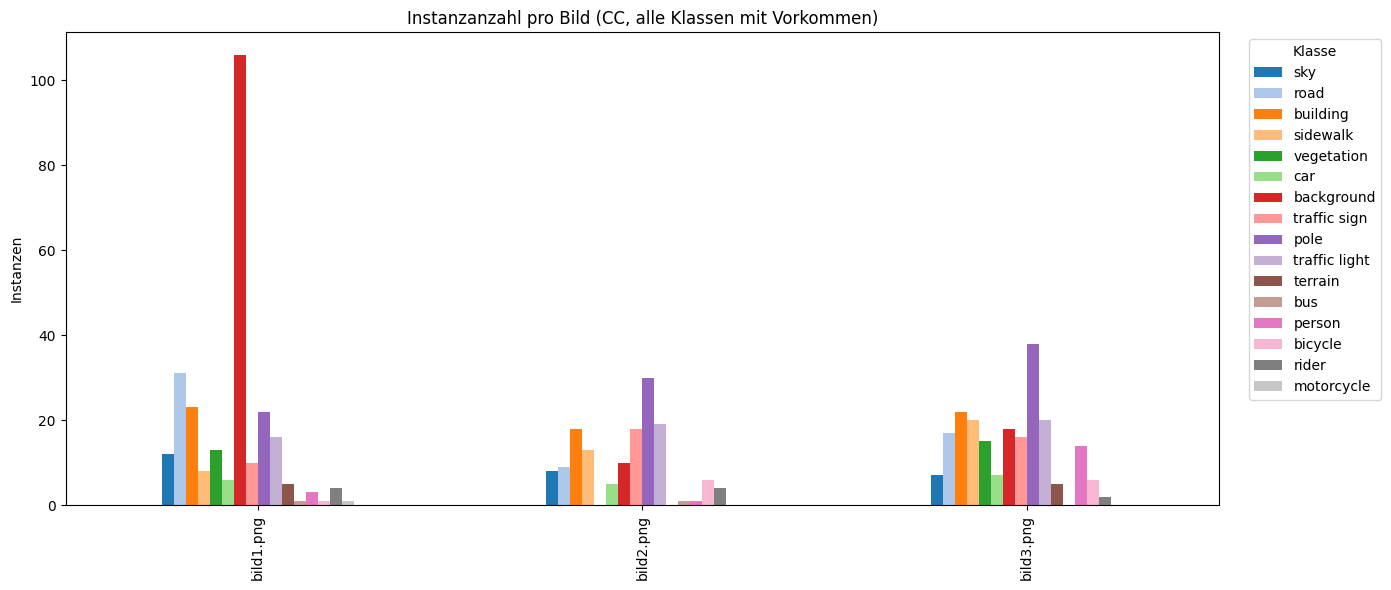

In [74]:
if SHOW_BASIC_PLOTS:
    def nice_barh(series, title):
        colors = [palette.get(idx, "steelblue") for idx in series.index]
        ax = plt.gca()
        series.plot(kind="barh", color=colors, ax=ax)
        ax.invert_yaxis()
        ax.set_title(title)
        for i, v in enumerate(series):
            ax.text(v, i, f" {v:.3f}" if v < 1 else f" {int(v)}", va="center")
        return ax

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    plt.sca(axes[0]); nice_barh(mean_shares.head(10), "Durchschnittlicher Pixelanteil (Top 10)")
    plt.sca(axes[1]); nice_barh(instances_df.sum().sort_values(ascending=False).head(10), "Gesamtanzahl Instanzen (Top 10, CC)")
    plt.tight_layout()
    plt.show()

if SHOW_PER_IMAGE_PLOTS:
    fig, ax = plt.subplots(figsize=(14, 6))
    shares_df[classes_for_plots].plot(kind="bar", stacked=True, ax=ax, color=[palette[c] for c in classes_for_plots])
    ax.set_ylabel("Pixelanteil")
    ax.set_title("Pixelanteile pro Bild (alle Klassen, gestapelt)")
    ax.legend(title="Klasse", bbox_to_anchor=(1.02, 1), loc="upper left")
    plt.tight_layout()
    plt.show()

    nonzero_classes = [c for c in classes_for_plots if instances_df[c].sum() > 0]
    fig, ax = plt.subplots(figsize=(14, 6))
    instances_df[nonzero_classes].plot(kind="bar", ax=ax, color=[palette[c] for c in nonzero_classes])
    ax.set_ylabel("Instanzen")
    ax.set_title("Instanzanzahl pro Bild (CC, alle Klassen mit Vorkommen)")
    ax.legend(title="Klasse", bbox_to_anchor=(1.02, 1), loc="upper left")
    plt.tight_layout()
    plt.show()


## Alternative Instanztrennung (Distance Transform + Watershed)

Kurze Notizen fuer mich, was hier passiert und was ich anpassen kann:
- Baseline ist CC. Watershed probiere ich nur fuer Objektklassen (INSTANCE_CLASSES).
- Ablauf: Binarmaske -> (optional) Erosion -> Distance Transform -> lokale Peaks als Seeds -> Watershed -> Instanzen zaehlen.
- WS_DIST_REL: Schwellwert fuer Seeds (relativ zum Max der Distance Map). Kleiner = mehr Seeds.
- WS_MIN_AREA: Filter fuer sehr kleine Fragmente. Groesser = weniger Noise.
- WS_ERODE_ITERS: Trennt schmale Bruecken zwischen Objekten.
- WS_USE_PEAKS: True nutzt lokale Maxima als Seeds; False nutzt nur Threshold.
- WS_PEAK_EPS: Toleranz fuer Peak-Vergleich (verhindert, dass Peaks verloren gehen).
- WS_SEED_OPEN_KERNEL: 1 = kein Open; groesser entfernt kleine Seeds (kann zu 0 Seeds fuehren).


In [75]:
def watershed_instance_counts(
    mask_path: Path,
    classes,
    dist_rel=0.20,
    min_area=6,
    erode_iters=1,
    use_peaks=True,
    peak_eps=1e-6,
    seed_open_kernel=1,
    instance_classes=None,
):
    if instance_classes is None:
        instance_classes = {c["name"] for c in classes}

    mask = np.array(Image.open(mask_path))
    if mask.ndim != 3 or mask.shape[2] != 3:
        raise ValueError(f"Maske {mask_path} hat unerwartete Form: {mask.shape}")

    counts = {c["name"]: 0 for c in classes}
    kernel = np.ones((3, 3), np.uint8)

    for rec in classes:
        name = rec["name"]
        color = np.array(rec["color"], dtype=np.uint8)
        binary = (np.all(mask == color, axis=2)).astype(np.uint8)
        if binary.sum() == 0:
            continue

        # Nur ausgewaehlte Klassen mit Watershed splitten
        if name not in instance_classes:
            continue

        work = binary.copy()
        if erode_iters > 0:
            work = cv2.erode(work, kernel, iterations=erode_iters)
            if work.sum() == 0:
                work = binary

        dist = cv2.distanceTransform(work, cv2.DIST_L2, 5)
        max_d = dist.max()
        if max_d <= 0:
            continue

        dist_norm = dist / max_d

        if use_peaks:
            dilated = cv2.dilate(dist, kernel)
            peaks = (dist >= (dilated - peak_eps)) & (dist_norm > dist_rel)
            seed_mask = peaks.astype(np.uint8)
        else:
            seed_mask = (dist_norm > dist_rel).astype(np.uint8)

        if seed_open_kernel and seed_open_kernel > 1:
            sk = np.ones((seed_open_kernel, seed_open_kernel), np.uint8)
            seed_mask = cv2.morphologyEx(seed_mask, cv2.MORPH_OPEN, sk)

        num_markers, markers = cv2.connectedComponents(seed_mask)
        if num_markers <= 1 and use_peaks:
            seed_mask = (dist_norm > dist_rel).astype(np.uint8)
            if seed_open_kernel and seed_open_kernel > 1:
                sk = np.ones((seed_open_kernel, seed_open_kernel), np.uint8)
                seed_mask = cv2.morphologyEx(seed_mask, cv2.MORPH_OPEN, sk)
            num_markers, markers = cv2.connectedComponents(seed_mask)

        if num_markers <= 1:
            continue

        markers = markers + 1
        markers[binary == 0] = 0

        img_for_ws = cv2.cvtColor((binary * 255).astype(np.uint8), cv2.COLOR_GRAY2BGR)
        markers = cv2.watershed(img_for_ws, markers)

        unique, areas = np.unique(markers, return_counts=True)
        ws_count = 0
        for lbl, area in zip(unique, areas):
            if lbl > 1 and area >= min_area:
                ws_count += 1

        counts[name] = ws_count

    counts["__image__"] = mask_path.name
    return counts

ws_rows = [
    watershed_instance_counts(
        png,
        classes,
        dist_rel=WS_DIST_REL,
        min_area=WS_MIN_AREA,
        erode_iters=WS_ERODE_ITERS,
        use_peaks=WS_USE_PEAKS,
        peak_eps=WS_PEAK_EPS,
        seed_open_kernel=WS_SEED_OPEN_KERNEL,
        instance_classes=INSTANCE_CLASSES,
    )
    for png in png_files
]

ws_instances_df = pd.DataFrame(ws_rows).set_index("__image__").fillna(0).astype(int)


## Visualisierung (Watershed)
Optional: globale Instanzsummen pro Klasse und per-Bild-Ansicht.


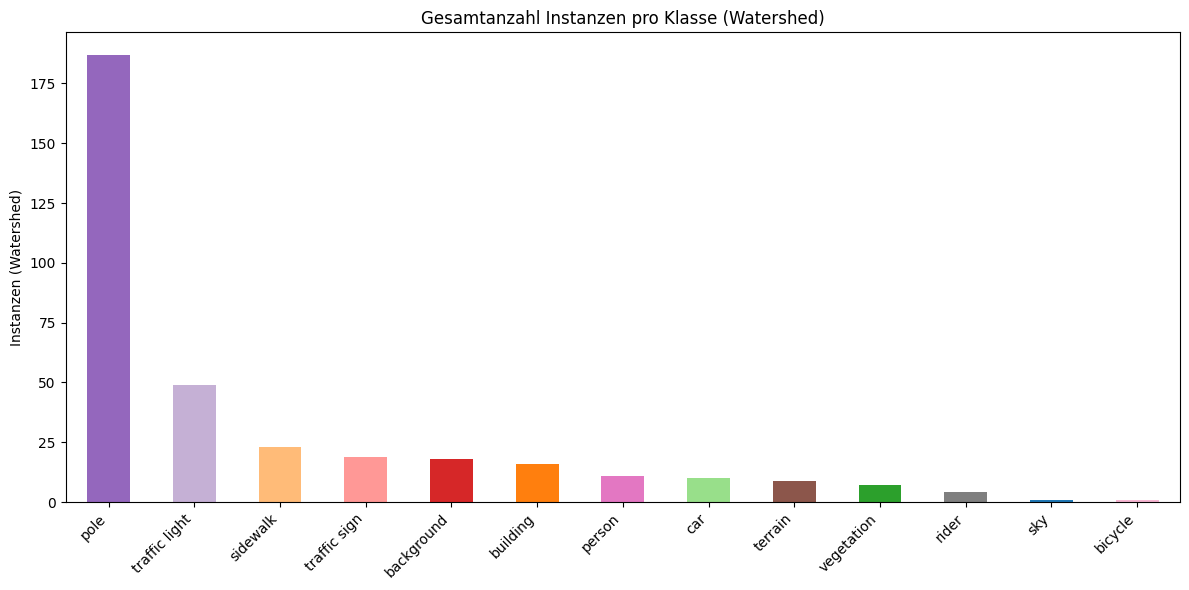

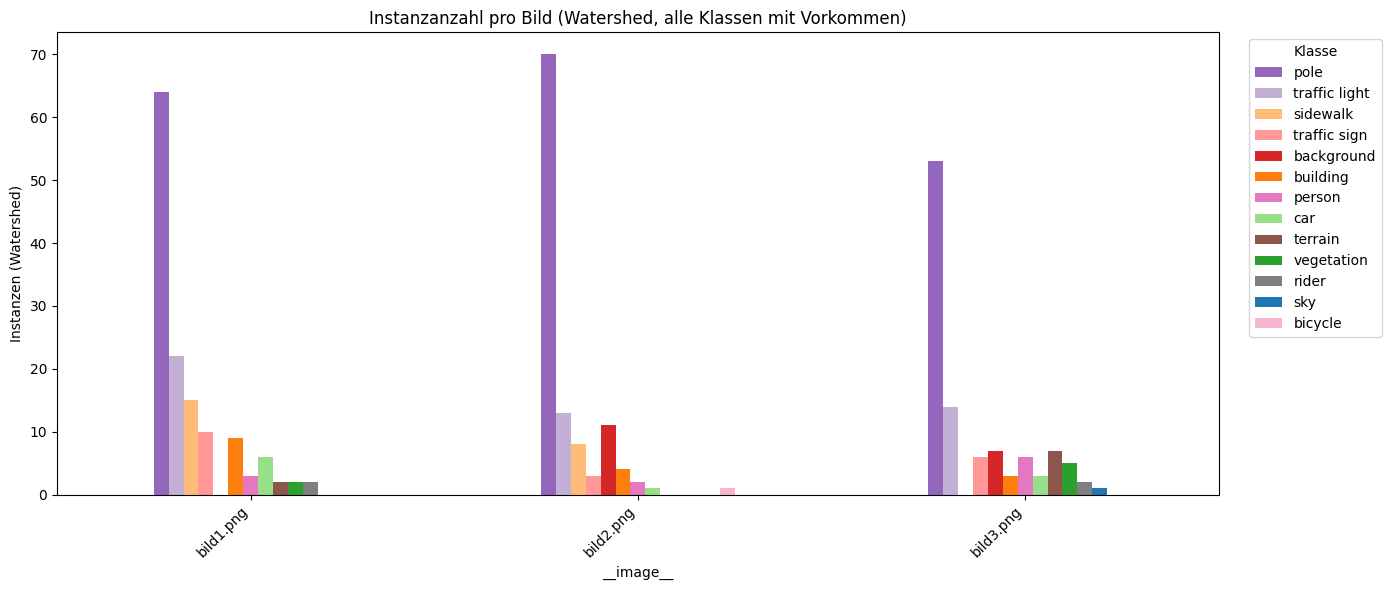

In [76]:
if SHOW_WS_PLOTS:
    ws_total = ws_instances_df.sum().sort_values(ascending=False)
    ws_classes = [c for c in ws_total.index if ws_total[c] > 0]

    fig, ax = plt.subplots(figsize=(12, 6))
    colors = [palette.get(c, "mediumseagreen") for c in ws_classes]
    ws_total[ws_classes].plot(kind="bar", color=colors, ax=ax)
    ax.set_ylabel("Instanzen (Watershed)")
    ax.set_title("Gesamtanzahl Instanzen pro Klasse (Watershed)")
    plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
    plt.tight_layout()
    plt.show()

    fig, ax = plt.subplots(figsize=(14, 6))
    ws_instances_df[ws_classes].plot(kind="bar", ax=ax, color=[palette.get(c, "mediumseagreen") for c in ws_classes])
    ax.set_ylabel("Instanzen (Watershed)")
    ax.set_title("Instanzanzahl pro Bild (Watershed, alle Klassen mit Vorkommen)")
    ax.legend(title="Klasse", bbox_to_anchor=(1.02, 1), loc="upper left")
    plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
    plt.tight_layout()
    plt.show()


## Gestapelte Instanzzahlen pro Bild (CC vs. Watershed)
Gestapelte Balken zeigen die Instanzsummen je Bild ueber alle Klassen. Farben folgen der Klassen-Palette.


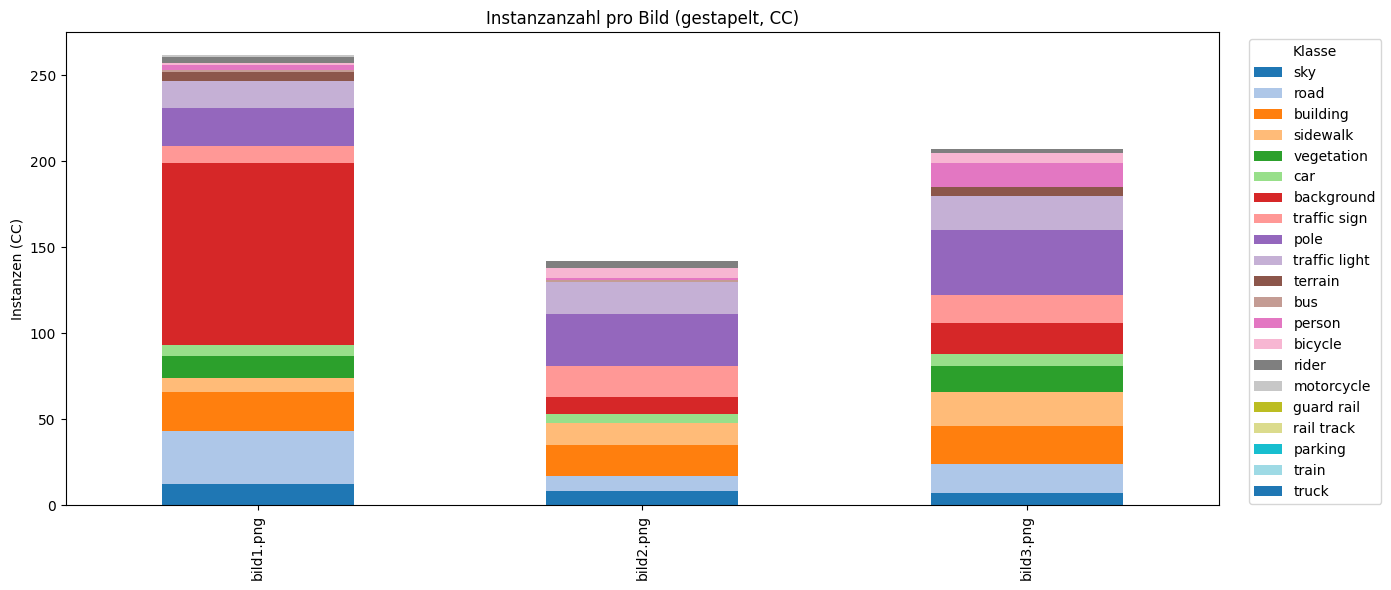

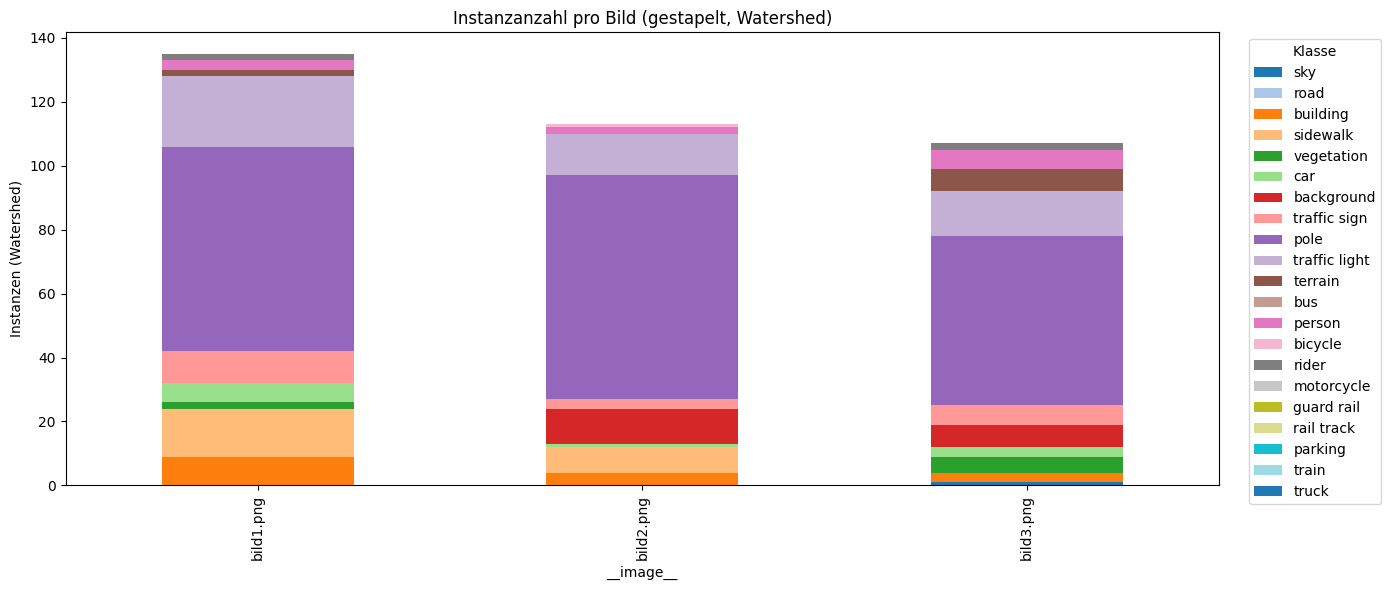

In [77]:
if SHOW_STACKED_INSTANCES:
    classes_order = classes_for_plots
    colors = [palette.get(c, "gray") for c in classes_order]

    cc_aligned = instances_df.reindex(columns=classes_order).fillna(0)
    ws_aligned = ws_instances_df.reindex(columns=classes_order).fillna(0)

    fig, ax = plt.subplots(figsize=(14, 6))
    cc_aligned.plot(kind="bar", stacked=True, ax=ax, color=colors)
    ax.set_ylabel("Instanzen (CC)")
    ax.set_title("Instanzanzahl pro Bild (gestapelt, CC)")
    ax.legend(title="Klasse", bbox_to_anchor=(1.02, 1), loc="upper left")
    plt.tight_layout()
    plt.show()

    fig, ax = plt.subplots(figsize=(14, 6))
    ws_aligned.plot(kind="bar", stacked=True, ax=ax, color=colors)
    ax.set_ylabel("Instanzen (Watershed)")
    ax.set_title("Instanzanzahl pro Bild (gestapelt, Watershed)")
    ax.legend(title="Klasse", bbox_to_anchor=(1.02, 1), loc="upper left")
    plt.tight_layout()
    plt.show()


## Peak-Detection basierte Instanzschaetzung (Distance Peaks)

Idee: Lokale Maxima der Distanztransformation als Objektzentren zaehlen. Falls `scikit-image` fehlt, wird ein cv2-Fallback genutzt.
Parameter anpassen ueber PEAK_*.


In [78]:
try:
    from skimage.feature import peak_local_max as sk_peak_local_max
except ImportError:
    sk_peak_local_max = None


def peak_local_max_fallback(dist, min_distance=6, threshold_rel=0.2, labels=None):
    if labels is not None:
        dist = dist.copy()
        dist[labels == 0] = 0
    max_d = float(dist.max())
    if max_d <= 0:
        return np.empty((0, 2), dtype=int)

    thresh = threshold_rel * max_d
    k = max(1, int(min_distance))
    kernel = np.ones((2 * k + 1, 2 * k + 1), np.uint8)

    dist32 = dist.astype(np.float32)
    dilated = cv2.dilate(dist32, kernel)
    peaks = (dist32 >= thresh) & (dist32 == dilated)

    if labels is not None:
        peaks = peaks & (labels > 0)

    peaks_u8 = peaks.astype(np.uint8)
    num, cc = cv2.connectedComponents(peaks_u8)
    if num <= 1:
        return np.empty((0, 2), dtype=int)

    coords = []
    for lbl in range(1, num):
        ys, xs = np.where(cc == lbl)
        if len(ys) == 0:
            continue
        idx = np.argmax(dist32[ys, xs])
        coords.append([ys[idx], xs[idx]])
    return np.array(coords, dtype=int)

if sk_peak_local_max is None:
    print("skimage fehlt, nutze cv2-basierten Fallback fuer Peaks.")


def peak_based_counts(
    mask_path: Path,
    classes,
    dist_rel=0.20,
    min_distance=6,
    erode_iters=1,
    instance_classes=None,
):
    if instance_classes is None:
        instance_classes = {c["name"] for c in classes}

    mask = np.array(Image.open(mask_path))
    if mask.ndim != 3 or mask.shape[2] != 3:
        raise ValueError(f"Maske {mask_path} hat unerwartete Form: {mask.shape}")

    counts = {c["name"]: 0 for c in classes}
    kernel = np.ones((3, 3), np.uint8)

    for rec in classes:
        name = rec["name"]
        color = np.array(rec["color"], dtype=np.uint8)
        binary = (np.all(mask == color, axis=2)).astype(np.uint8)
        if binary.sum() == 0:
            continue

        if name not in instance_classes:
            continue

        work = binary.copy()
        if erode_iters > 0:
            work = cv2.erode(work, kernel, iterations=erode_iters)
            if work.sum() == 0:
                work = binary

        dist = cv2.distanceTransform(work, cv2.DIST_L2, 5)
        max_d = dist.max()
        if max_d <= 0:
            continue

        if sk_peak_local_max is None:
            peaks = peak_local_max_fallback(
                dist,
                min_distance=min_distance,
                threshold_rel=dist_rel,
                labels=work,
            )
        else:
            peaks = sk_peak_local_max(
                dist,
                min_distance=min_distance,
                threshold_rel=dist_rel,
                labels=work,
                exclude_border=False,
            )

        counts[name] = len(peaks)

    counts["__image__"] = mask_path.name
    return counts

peak_rows = [
    peak_based_counts(
        png,
        classes,
        dist_rel=PEAK_DIST_REL,
        min_distance=PEAK_MIN_DISTANCE,
        erode_iters=PEAK_ERODE_ITERS,
        instance_classes=INSTANCE_CLASSES,
    )
    for png in png_files
]

peak_instances_df = pd.DataFrame(peak_rows).set_index("__image__").fillna(0).astype(int)


skimage fehlt, nutze cv2-basierten Fallback fuer Peaks.


## Pro Bild: Instanzplots je Methode (CC, Watershed, Peaks)
Fuer jedes Bild werden drei Balkendiagramme erzeugt (CC/Watershed/Peaks). Optional begrenzen ueber `PER_IMAGE_MAX`.


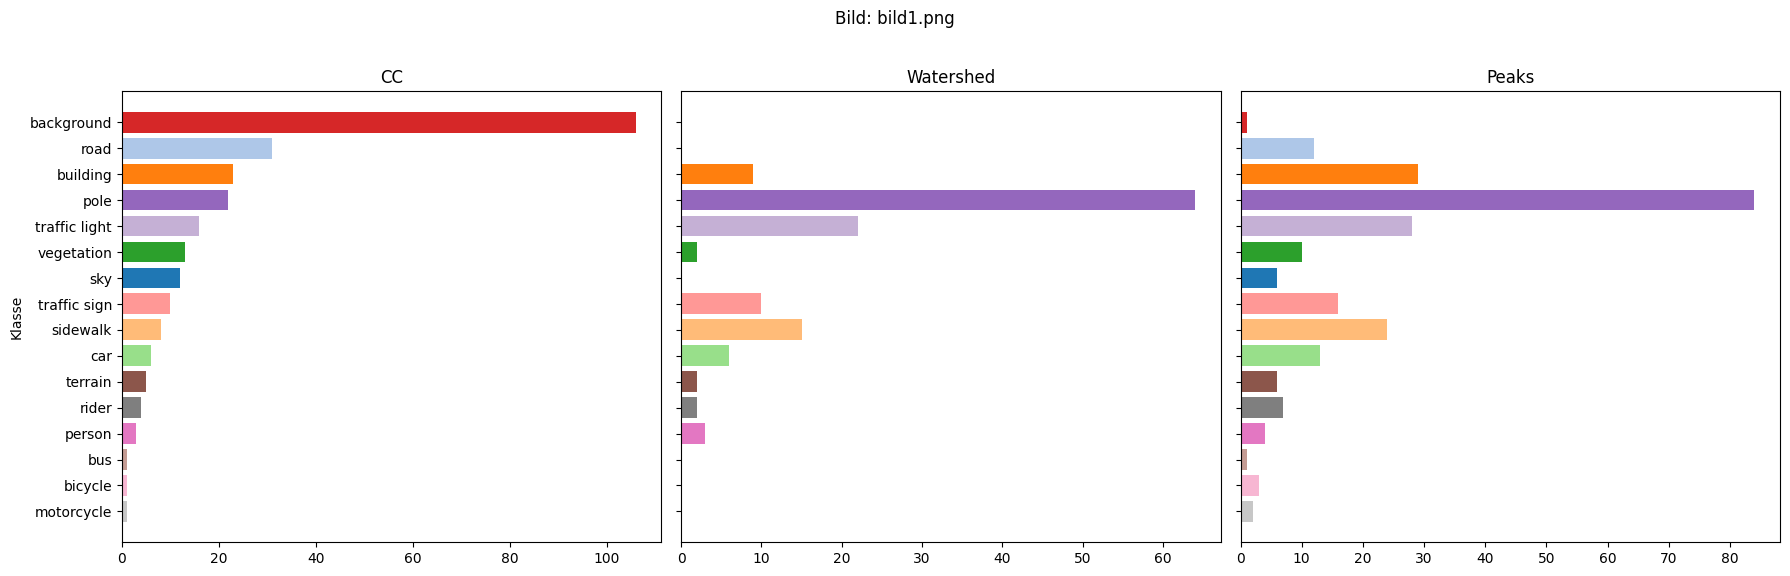

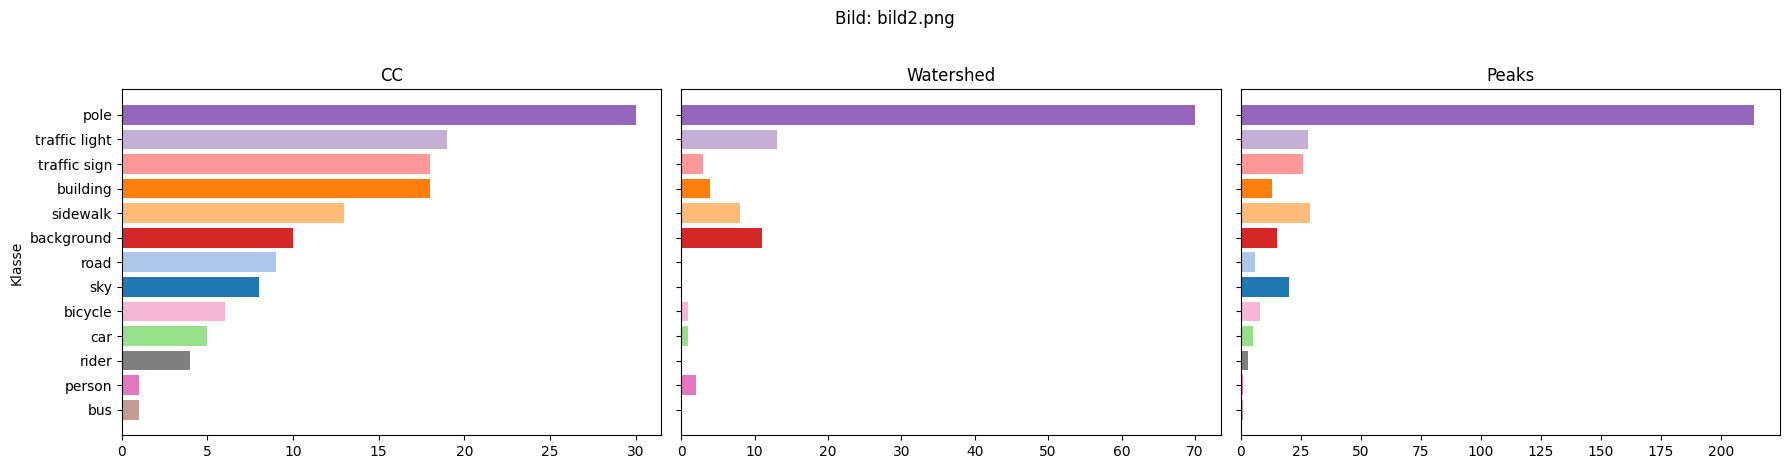

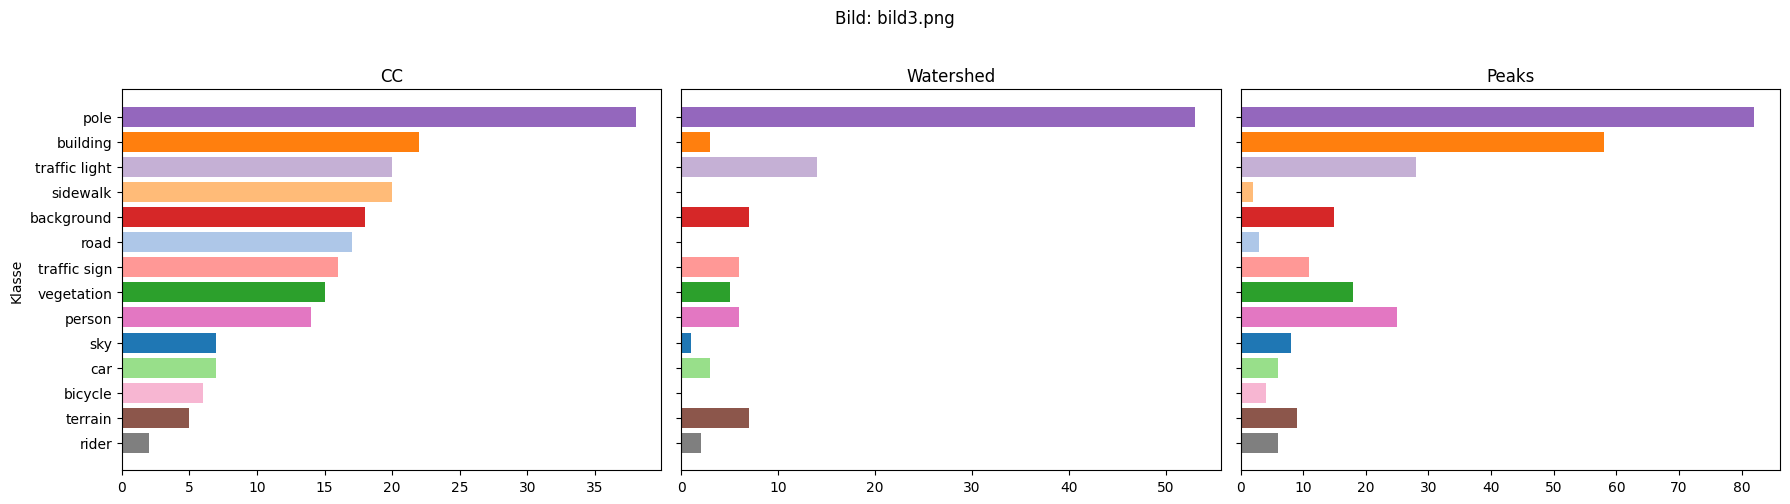

In [79]:
if SHOW_PER_IMAGE_METHODS:
    # Klassenliste: alle oder nur INSTANCE_CLASSES
    if SHOW_FINAL_ALL_CLASSES:
        base_classes = classes_for_plots
    else:
        if INSTANCE_CLASSES is None:
            base_classes = classes_for_plots
        else:
            base_classes = sorted(INSTANCE_CLASSES)

    images = list(instances_df.index)
    if PER_IMAGE_MAX is not None:
        images = images[:PER_IMAGE_MAX]

    for img in images:
        cc_vals = instances_df.reindex(columns=base_classes).loc[img].fillna(0)
        ws_vals = ws_instances_df.reindex(columns=base_classes).loc[img].fillna(0)
        peak_vals = peak_instances_df.reindex(columns=base_classes).loc[img].fillna(0)

        # nur aktive Klassen zeigen
        active = [c for c in base_classes if (cc_vals[c] + ws_vals[c] + peak_vals[c]) > 0]
        if not active:
            continue

        order = cc_vals.reindex(active).sort_values(ascending=False).index.tolist()
        colors = [palette.get(c, "gray") for c in order]

        fig, axes = plt.subplots(1, 3, figsize=(18, max(4, len(order) * 0.35)), sharey=True)
        for ax, series, title in zip(
            axes,
            [cc_vals, ws_vals, peak_vals],
            ["CC", "Watershed", "Peaks"],
        ):
            s = series.reindex(order)
            ax.barh(order, s.values, color=colors)
            ax.set_title(f"{title}")
            ax.invert_yaxis()
        axes[0].set_ylabel("Klasse")
        plt.suptitle(f"Bild: {img}", y=1.02)
        plt.tight_layout()
        plt.show()


## Finale Zusammenfassung
Vergleich der Instanzmethoden (CC, Watershed, Peaks) nur fuer die Instanzklassen.


In [80]:
if SHOW_FINAL_SUMMARY:
    if INSTANCE_CLASSES is None:
        inst_list = classes_for_plots
    else:
        inst_list = sorted(INSTANCE_CLASSES)

    cc_total = instances_df.sum().reindex(inst_list).fillna(0).astype(int)
    ws_total = ws_instances_df.sum().reindex(inst_list).fillna(0).astype(int)
    peak_total = peak_instances_df.sum().reindex(inst_list).fillna(0).astype(int)

    final_df = pd.DataFrame({
        "cc_total": cc_total,
        "ws_total": ws_total,
        "peak_total": peak_total,
        "ws_minus_cc": ws_total - cc_total,
        "peak_minus_cc": peak_total - cc_total,
    }).sort_values("ws_minus_cc", ascending=False)

    display(final_df)


,cc_total,ws_total,peak_total,ws_minus_cc,peak_minus_cc
pole,90,187,380,97,290
truck,0,0,0,0,0
train,0,0,0,0,0
parking,0,0,0,0,0
rail track,0,0,0,0,0
guard rail,0,0,0,0,0
motorcycle,1,0,2,-1,1
terrain,10,9,15,-1,5
bus,2,0,2,-2,0
rider,10,4,16,-6,6


## Finale Visualisierungen (Instanzen, alle Objektklassen)
Mehrere Uebersichten ueber die Instanzsummen pro Klasse (CC/Watershed/Peaks).
Hinweis: Fuer viele Klassen ist `FINAL_TOP_CLASSES` hilfreich, damit die Diagramme lesbar bleiben.


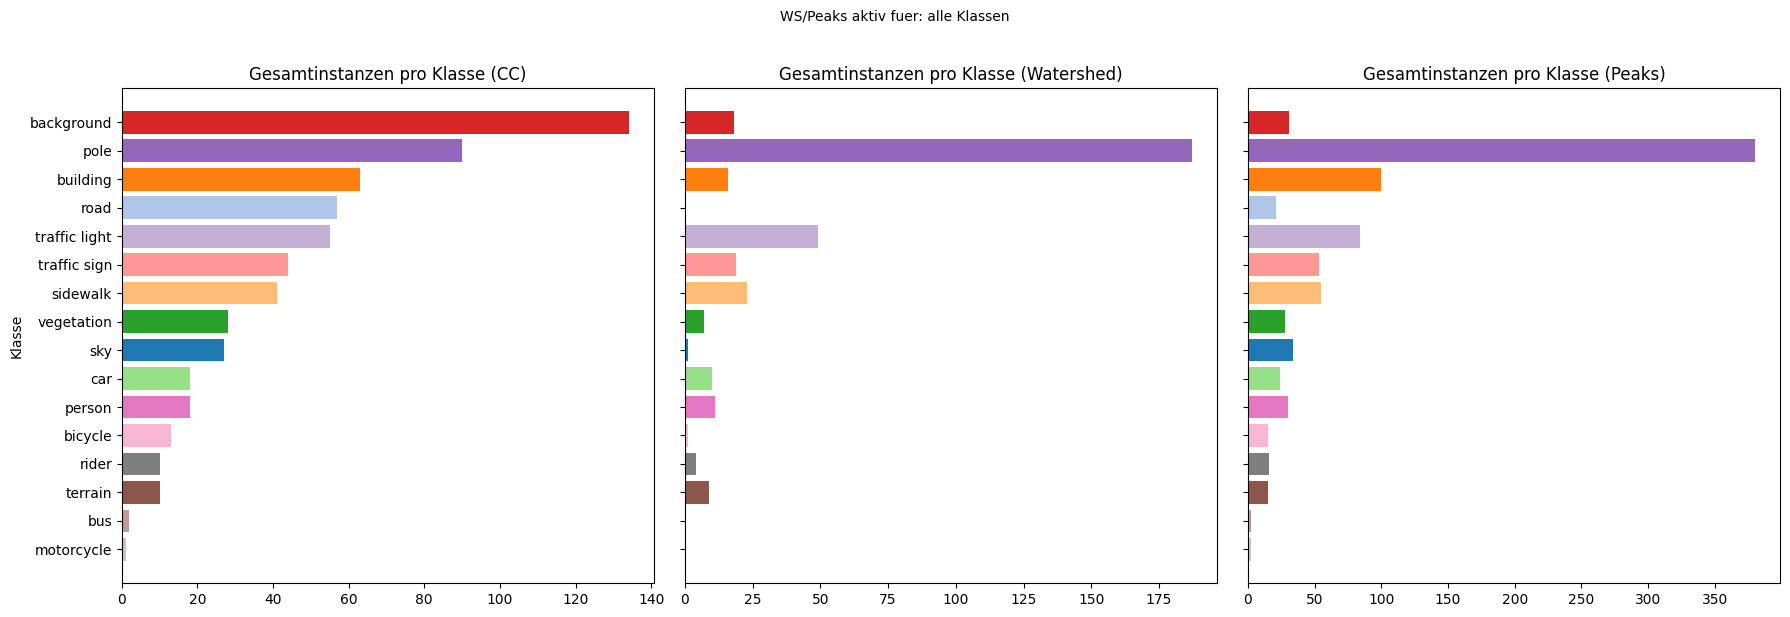

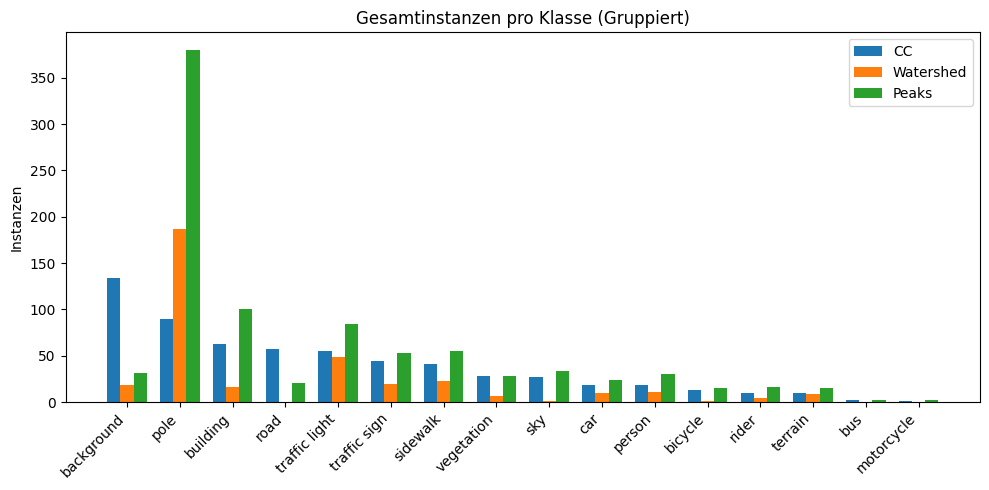

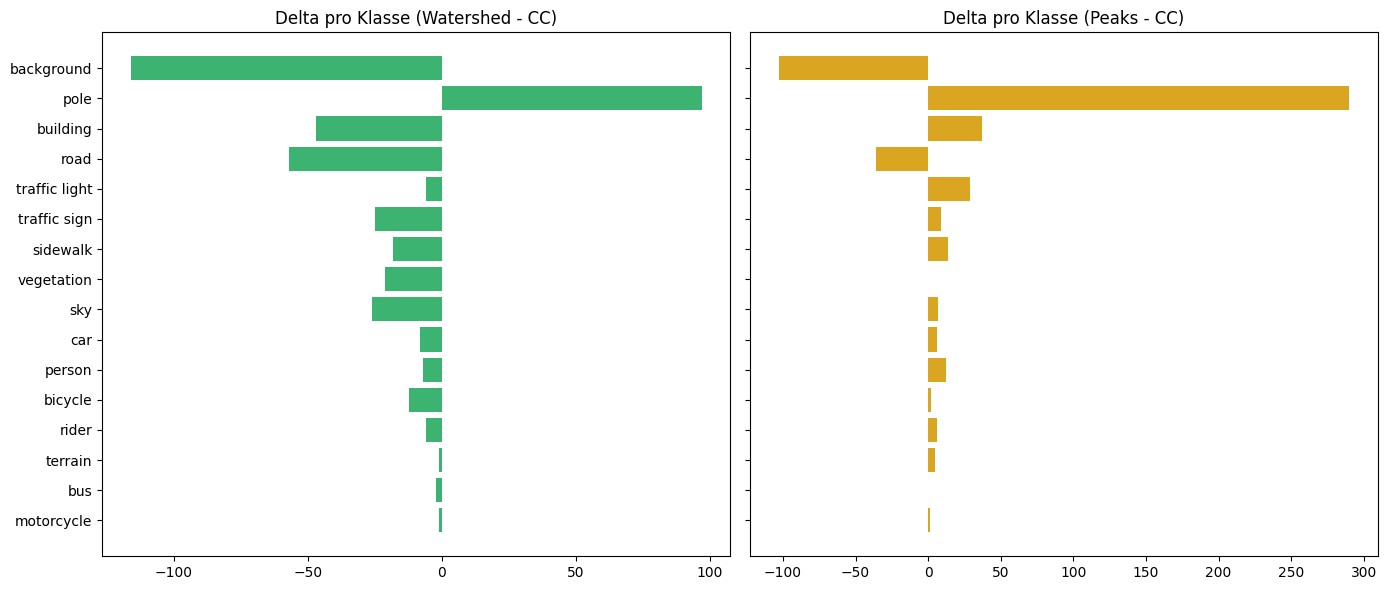

In [81]:
if SHOW_FINAL_VISUALS:
    # Alle Klassen oder nur INSTANCE_CLASSES?
    if SHOW_FINAL_ALL_CLASSES or INSTANCE_CLASSES is None:
        inst_list = classes_for_plots
    else:
        inst_list = sorted(INSTANCE_CLASSES)

    cc_total = instances_df.sum().reindex(inst_list).fillna(0).astype(int)
    ws_total = ws_instances_df.sum().reindex(inst_list).fillna(0).astype(int)
    peak_total = peak_instances_df.sum().reindex(inst_list).fillna(0).astype(int)

    active = [c for c in inst_list if (cc_total[c] + ws_total[c] + peak_total[c]) > 0]
    if not active:
        print("Keine Instanzen gefunden.")
    else:
        order = cc_total.reindex(active).sort_values(ascending=False).index.tolist()
        if FINAL_TOP_CLASSES:
            order = order[:FINAL_TOP_CLASSES]

        colors = [palette.get(c, "gray") for c in order]

        used_note = "WS/Peaks aktiv fuer: alle Klassen" if INSTANCE_CLASSES is None else (
            "WS/Peaks aktiv fuer: " + ", ".join(sorted(INSTANCE_CLASSES))
        )

        # 1) Gesamtsummen pro Klasse: drei Panel (CC / Watershed / Peaks)
        fig, axes = plt.subplots(1, 3, figsize=(18, 6), sharey=True)
        for ax, series, title in zip(
            axes,
            [cc_total, ws_total, peak_total],
            ["CC", "Watershed", "Peaks"],
        ):
            s = series.reindex(order)
            ax.barh(order, s.values, color=colors)
            ax.set_title(f"Gesamtinstanzen pro Klasse ({title})")
            ax.invert_yaxis()
        axes[0].set_ylabel("Klasse")
        plt.suptitle(used_note, y=1.02, fontsize=10)
        plt.tight_layout()
        plt.show()

        # 2) Gruppiertes Balkendiagramm pro Klasse (CC/WS/Peaks)
        x = np.arange(len(order))
        width = 0.25
        fig, ax = plt.subplots(figsize=(max(10, len(order) * 0.6), 5))
        ax.bar(x - width, cc_total.reindex(order).values, width, label="CC")
        ax.bar(x, ws_total.reindex(order).values, width, label="Watershed")
        ax.bar(x + width, peak_total.reindex(order).values, width, label="Peaks")
        ax.set_xticks(x)
        ax.set_xticklabels(order, rotation=45, ha="right")
        ax.set_ylabel("Instanzen")
        ax.set_title("Gesamtinstanzen pro Klasse (Gruppiert)")
        ax.legend()
        plt.tight_layout()
        plt.show()

        # 3) Delta pro Klasse (WS-CC und Peaks-CC)
        delta_ws = (ws_total - cc_total).reindex(order)
        delta_peak = (peak_total - cc_total).reindex(order)

        fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharey=True)
        axes[0].barh(order, delta_ws.values, color="mediumseagreen")
        axes[0].set_title("Delta pro Klasse (Watershed - CC)")
        axes[0].invert_yaxis()
        axes[1].barh(order, delta_peak.values, color="goldenrod")
        axes[1].set_title("Delta pro Klasse (Peaks - CC)")
        plt.tight_layout()
        plt.show()
